In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path
import os

# Configuration settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['font.size'] = 12
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.family'] = 'DejaVu Sans'

# 1. Data Loadin

In [12]:
def load_results():
    """Load CSV files from the results folder"""
    results_dir = Path("results")
    
    # Find the most recent CSV files
    detail_files = list(results_dir.glob("benaloh_performance_results_20260823_180220.csv"))
    summary_files = list(results_dir.glob("benaloh_summary_results_20260823_180220.csv"))
    
    if not detail_files or not summary_files:
        print("No CSV files found in the 'results' folder!")
        print("Please run the main code first to generate CSV files.")
        return None, None
    
    # Select the most recent files
    detail_file = max(detail_files, key=os.path.getctime)
    summary_file = max(summary_files, key=os.path.getctime)
    
    print(f"Loading detailed results: {detail_file.name}")
    print(f"Loading summary results: {summary_file.name}")
    
    df_detail = pd.read_csv(detail_file)
    df_summary = pd.read_csv(summary_file)
    
    return df_detail, df_summary

# Load the data
df_detail, df_summary = load_results()

if df_detail is not None:
    print("\nSample of detailed data:")
    print(df_detail.head())
    print("\nSample of summary data:")
    print(df_summary.head())

Loading detailed results: benaloh_performance_results_20260823_180220.csv
Loading summary results: benaloh_summary_results_20260823_180220.csv

Sample of detailed data:
   bits  num_clients         phase  avg_time_ms  std_time_ms  min_time_ms  \
0   256          100         setup      33.8433      10.1443      25.0037   
1   256          100  registration       1.6618       0.6500       0.9978   
2   256          100    encryption      27.2437       7.2154      21.0044   
3   256          100   aggregation      55.1685      14.3999      44.0104   
4   256          100    decryption       1.0871       0.4437       0.0000   

   max_time_ms  median_time_ms  
0      76.2990         30.1275  
1       3.9985          1.9993  
2      58.4919         24.1907  
3     113.4274         49.0712  
4       2.0225          1.0004  

Sample of summary data:
   bits  num_clients  total_avg_ms  total_std_ms  total_min_ms  total_max_ms  \
0   256          100      119.0243       31.5026       94.0232   

In [13]:
# ============================================================================
# 2. Helper Functions for Plotting
# ============================================================================

def create_comparison_plots(df_summary):
    """Create main comparison plots"""
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('Benaloh Performance Comparison Across Key Lengths and Client Counts', 
                 fontsize=16, fontweight='bold')
    
    # 1. Bar chart - Total time comparison by key length and client count
    ax = axes[0, 0]
    pivot = df_summary.pivot(index='bits', columns='num_clients', values='total_avg_ms')
    pivot.plot(kind='bar', ax=ax)
    ax.set_title('Total Time (Average) by Key Length and Client Count')
    ax.set_xlabel('Key Length (bits)')
    ax.set_ylabel('Time (milliseconds)')
    ax.legend(title='Number of Clients')
    ax.grid(True, alpha=0.3)
    
    # 2. Line chart - Scalability with client count
    ax = axes[0, 1]
    for bits in sorted(df_summary['bits'].unique()):
        data = df_summary[df_summary['bits'] == bits]
        ax.plot(data['num_clients'], data['total_avg_ms'], marker='o', label=f'{bits}-bit')
    ax.set_title('Scalability with Increasing Number of Clients')
    ax.set_xlabel('Number of Clients')
    ax.set_ylabel('Total Time (milliseconds)')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # 3. Bubble chart - Combined effect of key length and client count
    ax = axes[1, 0]
    scatter = ax.scatter(df_summary['bits'], df_summary['num_clients'], 
                        s=df_summary['total_avg_ms']/10, 
                        c=df_summary['total_avg_ms'], 
                        cmap='viridis', alpha=0.6)
    ax.set_title('Combined Effect of Key Length and Client Count on Total Time')
    ax.set_xlabel('Key Length (bits)')
    ax.set_ylabel('Number of Clients')
    plt.colorbar(scatter, ax=ax, label='Total Time (milliseconds)')
    
    # 4. Breakdown chart - Time distribution across phases
    ax = axes[1, 1]
    phases = ['setup', 'registration', 'encryption', 'aggregation', 'decryption']
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']
    
    # Select a sample configuration for display
    sample_config = df_summary[(df_summary['bits'] == 256) & (df_summary['num_clients'] == 100)]
    if not sample_config.empty:
        values = [sample_config[f'{phase}_avg_ms'].values[0] for phase in phases]
        bars = ax.bar(phases, values, color=colors)
        ax.set_title('Phase Breakdown (Sample: 256-bit, 100 clients)')
        ax.set_ylabel('Time (milliseconds)')
        ax.grid(True, alpha=0.3, axis='y')
        
        # Add values on top of bars
        for bar, val in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
                   f'{val:.1f}', ha='center', va='bottom')
    
    plt.tight_layout()
    plt.savefig('results/performance_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()

def create_heatmap(df_summary):
    """Heatmap for parameter effect visualization"""
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('Heatmap of Parameter Effects on Performance', fontsize=16, fontweight='bold')
    
    # 1. Heatmap for total time
    ax = axes[0]
    pivot_total = df_summary.pivot(index='bits', columns='num_clients', values='total_avg_ms')
    sns.heatmap(pivot_total, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax, 
                cbar_kws={'label': 'Total Time (milliseconds)'})
    ax.set_title('Total Time by Key Length and Client Count')
    ax.set_xlabel('Number of Clients')
    ax.set_ylabel('Key Length (bits)')
    
    # 2. Heatmap for encryption time
    ax = axes[1]
    pivot_enc = df_summary.pivot(index='bits', columns='num_clients', values='encryption_avg_ms')
    sns.heatmap(pivot_enc, annot=True, fmt='.1f', cmap='Blues', ax=ax, 
                cbar_kws={'label': 'Encryption Time (milliseconds)'})
    ax.set_title('Encryption Time by Key Length and Client Count')
    ax.set_xlabel('Number of Clients')
    ax.set_ylabel('Key Length (bits)')
    
    plt.tight_layout()
    plt.savefig('results/performance_heatmap.png', dpi=300, bbox_inches='tight')
    plt.show()

def create_phase_comparison(df_summary):
    """Compare different phases across configurations"""
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('Phase Comparison Across Different Configurations', fontsize=16, fontweight='bold')
    
    phases = ['setup', 'registration', 'encryption', 'aggregation', 'decryption']
    phase_labels = ['Setup', 'Registration', 'Encryption', 'Aggregation', 'Decryption']
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']
    
    # Select sample configurations
    configs = [
        (256, 100), (256, 200), (256, 300),
        (512, 100), (512, 200), (512, 300),
        (1024, 100), (1024, 200), (1024, 300)
    ]
    
    # 1. Grouped bar chart for each configuration
    ax = axes[0, 0]
    x = np.arange(len(phases))
    width = 0.08
    
    for i, (bits, num_clients) in enumerate(configs[:5]):
        data = df_summary[(df_summary['bits'] == bits) & (df_summary['num_clients'] == num_clients)]
        if not data.empty:
            values = [data[f'{phase}_avg_ms'].values[0] for phase in phases]
            ax.bar(x + i*width, values, width, label=f'{bits}-bit, {num_clients} clients')
    
    ax.set_xlabel('Execution Phases')
    ax.set_ylabel('Time (milliseconds)')
    ax.set_title('Phase Comparison Across Configurations')
    ax.set_xticks(x + width*2)
    ax.set_xticklabels(phase_labels)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    
    # 2. Pie chart - Phase distribution
    ax = axes[0, 1]
    config_256_100 = df_summary[(df_summary['bits'] == 256) & (df_summary['num_clients'] == 100)]
    if not config_256_100.empty:
        values_256 = [config_256_100[f'{phase}_avg_ms'].values[0] for phase in phases]
        ax.pie(values_256, labels=phase_labels, autopct='%1.1f%%', colors=colors)
        ax.set_title('Phase Distribution (256-bit, 100 clients)')
    
    # 3. Comparison across key lengths
    ax = axes[1, 0]
    for phase, label in zip(phases, phase_labels):
        data_256 = df_summary[df_summary['bits'] == 256].groupby('num_clients')[f'{phase}_avg_ms'].mean()
        data_512 = df_summary[df_summary['bits'] == 512].groupby('num_clients')[f'{phase}_avg_ms'].mean()
        data_1024 = df_summary[df_summary['bits'] == 1024].groupby('num_clients')[f'{phase}_avg_ms'].mean()
        
        ax.plot(data_256.index, data_256.values, marker='o', label=f'{label} (256-bit)')
        ax.plot(data_512.index, data_512.values, marker='s', label=f'{label} (512-bit)')
        ax.plot(data_1024.index, data_1024.values, marker='^', label=f'{label} (1024-bit)')
    
    ax.set_xlabel('Number of Clients')
    ax.set_ylabel('Time (milliseconds)')
    ax.set_title('Phase Comparison Across Key Lengths')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(True, alpha=0.3)
    
    # 4. Total time with standard deviation
    ax = axes[1, 1]
    for bits in sorted(df_summary['bits'].unique()):
        data = df_summary[df_summary['bits'] == bits]
        ax.errorbar(data['num_clients'], data['total_avg_ms'], 
                   yerr=data['total_std_ms'], marker='o', capsize=5, label=f'{bits}-bit')
    ax.set_title('Total Time with Standard Deviation')
    ax.set_xlabel('Number of Clients')
    ax.set_ylabel('Time (milliseconds)')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('results/phase_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()

def create_scalability_analysis(df_summary):
    """Scalability analysis and plotting"""
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('System Scalability Analysis', fontsize=16, fontweight='bold')
    
    # 1. Growth rate with increasing clients
    ax = axes[0]
    growth_rates = []
    
    for bits in sorted(df_summary['bits'].unique()):
        data = df_summary[df_summary['bits'] == bits].sort_values('num_clients')
        if len(data) > 1:
            base_time = data.iloc[0]['total_avg_ms']
            for _, row in data.iterrows():
                growth_rate = row['total_avg_ms'] / base_time
                ax.scatter(row['num_clients'], growth_rate, label=f'{bits}-bit' if _ == 0 else "")
                growth_rates.append({'bits': bits, 'num_clients': row['num_clients'], 'growth_rate': growth_rate})
    
    ax.set_xlabel('Number of Clients')
    ax.set_ylabel('Growth Rate (relative to base)')
    ax.set_title('Growth Rate of Execution Time with Increasing Clients')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # 2. Encryption efficiency per client
    ax = axes[1]
    for bits in sorted(df_summary['bits'].unique()):
        data = df_summary[df_summary['bits'] == bits]
        per_client_time = data['encryption_avg_ms'] / data['num_clients']
        ax.plot(data['num_clients'], per_client_time, marker='o', label=f'{bits}-bit')
    
    ax.set_xlabel('Number of Clients')
    ax.set_ylabel('Encryption Time per Client (milliseconds)')
    ax.set_title('Encryption Efficiency per Client')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('results/scalability_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

def create_statistical_summary(df_summary):
    """Statistical analysis and box plots"""
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('Statistical Analysis of Results', fontsize=16, fontweight='bold')
    
    # 1. Box plot for total time
    ax = axes[0]
    data_for_box = []
    labels = []
    
    for bits in sorted(df_summary['bits'].unique()):
        for num_clients in sorted(df_summary['num_clients'].unique()):
            data = df_summary[(df_summary['bits'] == bits) & (df_summary['num_clients'] == num_clients)]
            if not data.empty:
                data_for_box.append(data['total_avg_ms'].values[0])
                labels.append(f'{bits}-{num_clients}')
    
    if data_for_box:
        bp = ax.boxplot(data_for_box, labels=labels, patch_artist=True)
        for patch in bp['boxes']:
            patch.set_facecolor('lightblue')
        ax.set_xticklabels(labels, rotation=45, ha='right')
        ax.set_ylabel('Total Time (milliseconds)')
        ax.set_title('Total Time Distribution Across Configurations')
        ax.grid(True, alpha=0.3, axis='y')
    
    # 2. Correlation analysis
    ax = axes[1]
    correlation_data = df_summary[['bits', 'num_clients', 'total_avg_ms', 'encryption_avg_ms', 'aggregation_avg_ms']]
    correlation_matrix = correlation_data.corr()
    
    sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
    ax.set_title('Correlation Matrix Between Parameters')
    
    plt.tight_layout()
    plt.savefig('results/statistical_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()


Generating Performance Analysis Charts

1. Creating main comparison plots...


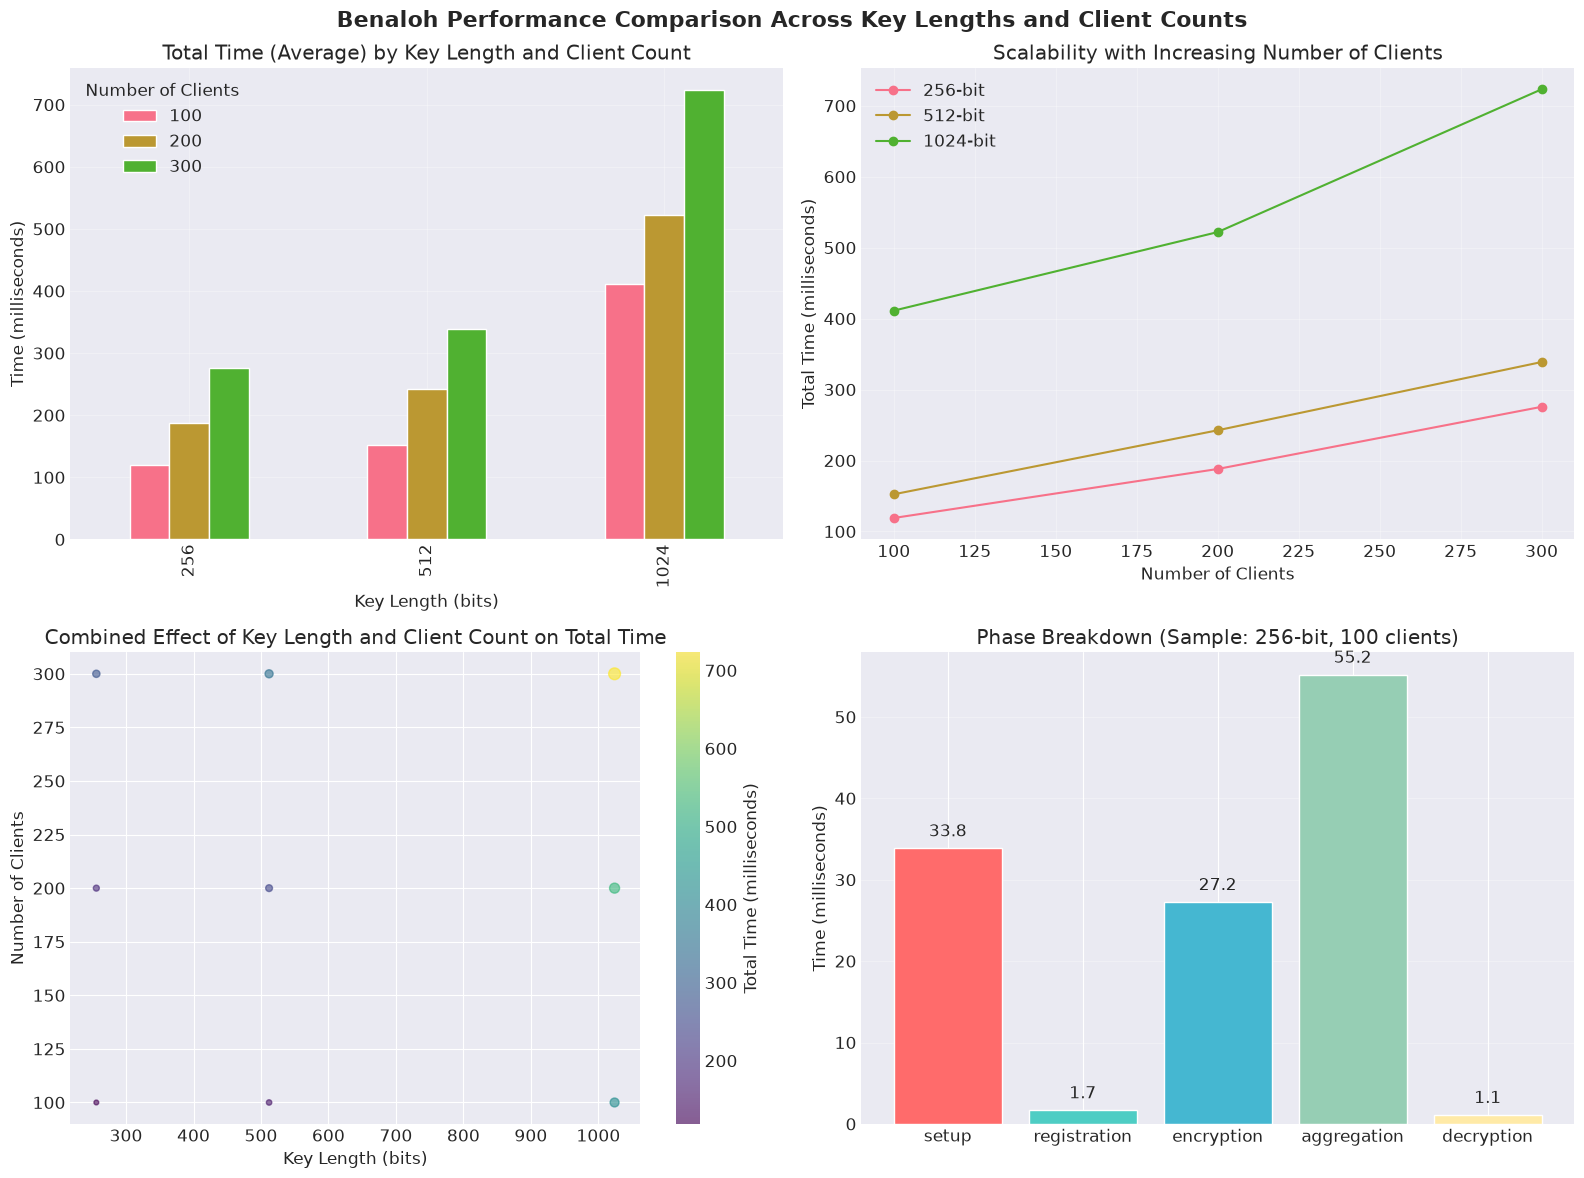

2. Creating heatmap plots...


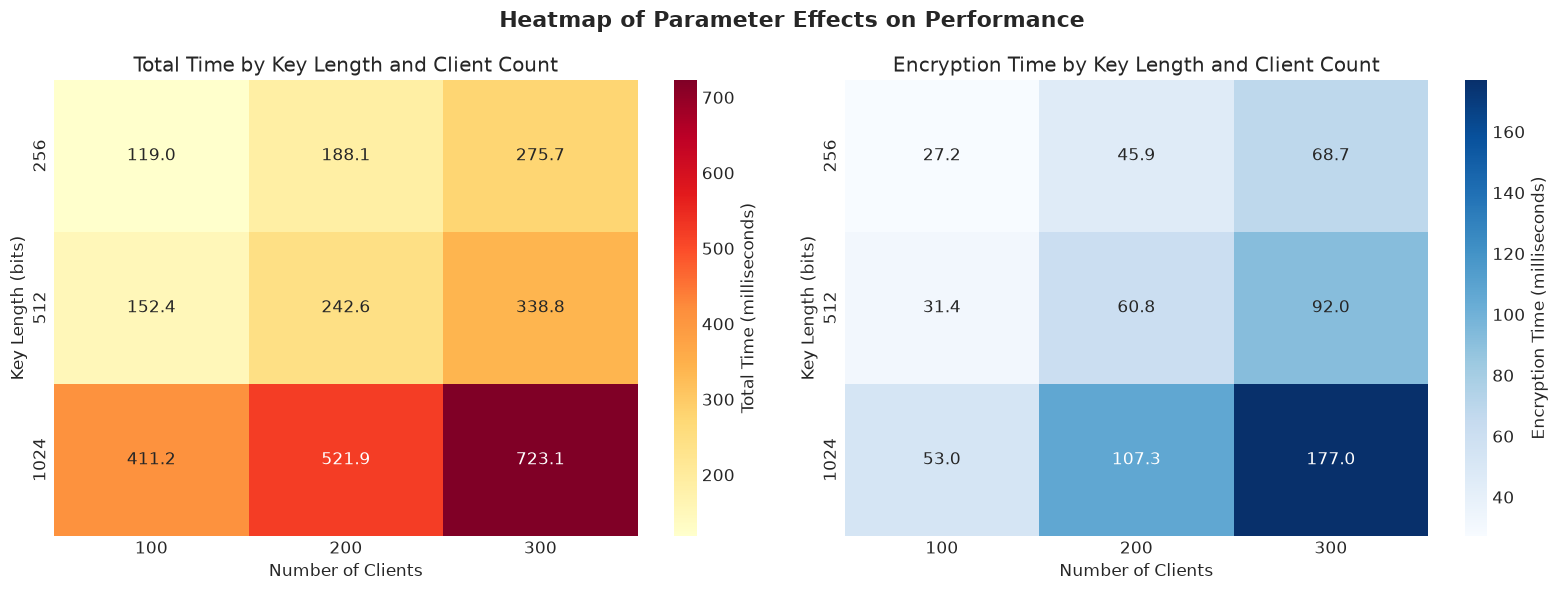

3. Creating phase comparison plots...


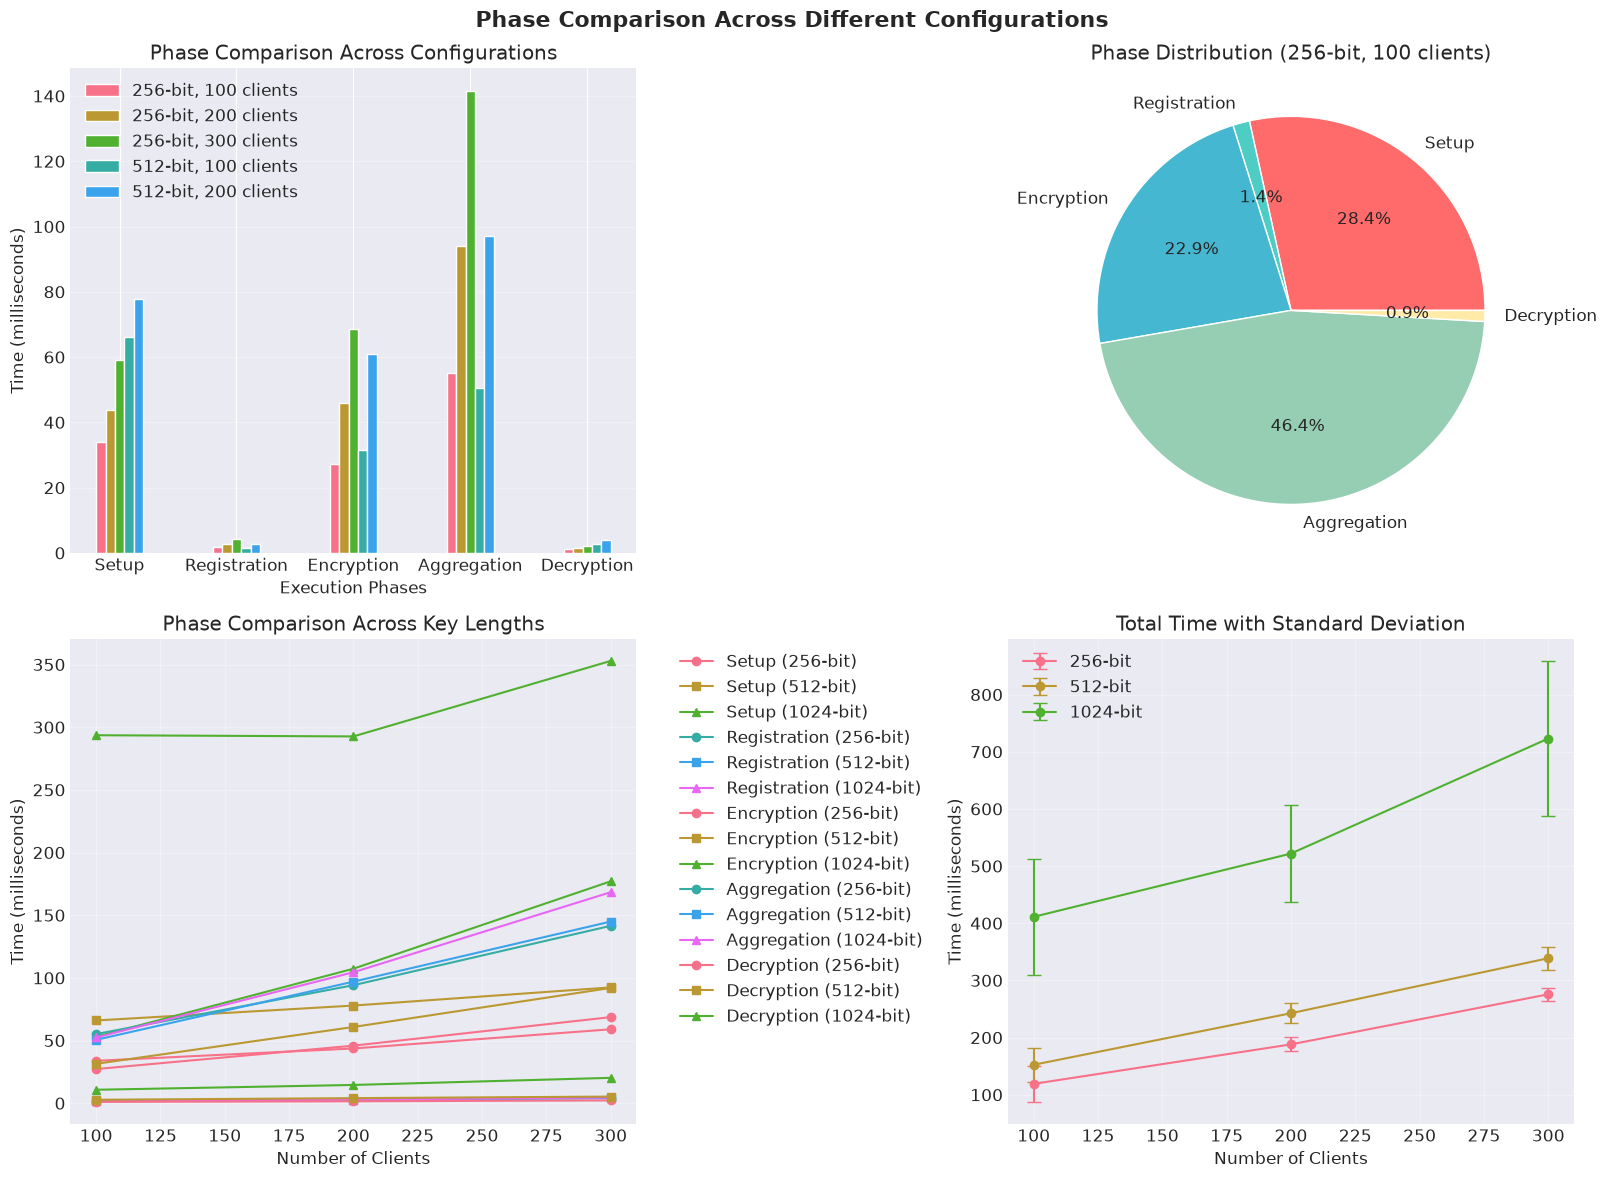

4. Creating scalability analysis plots...


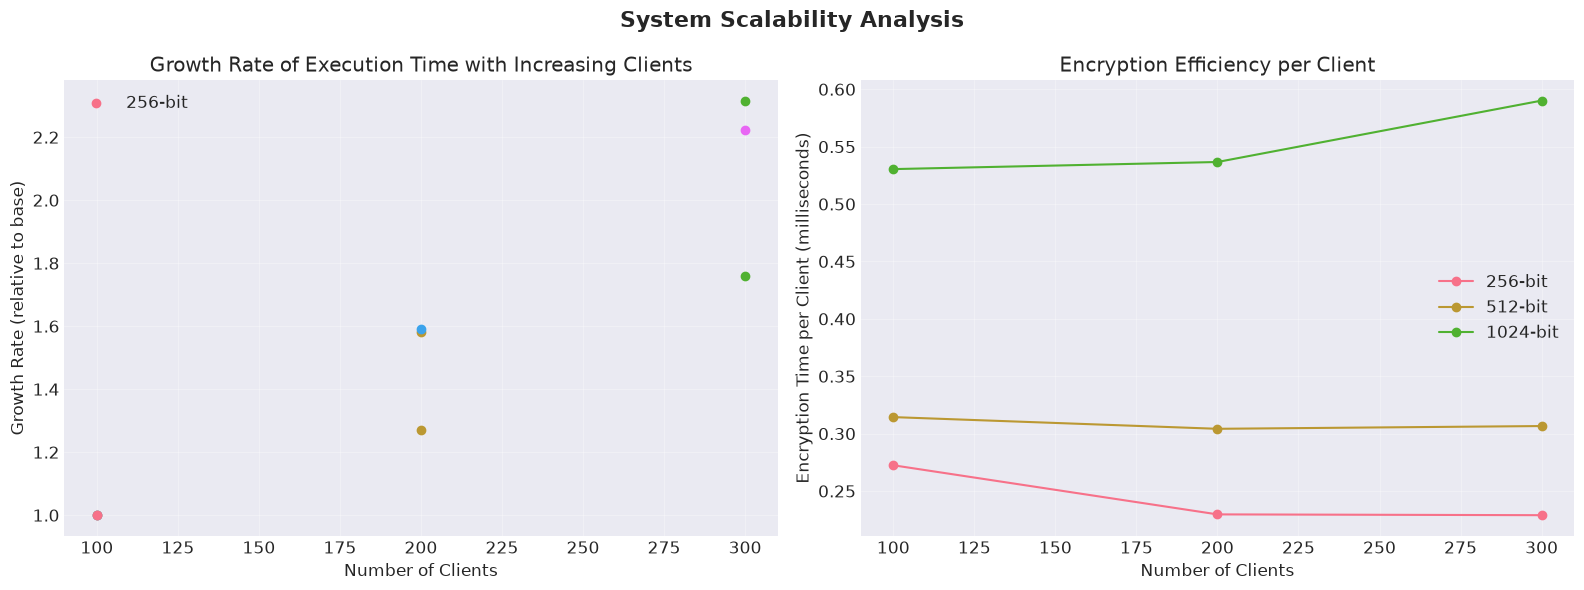

5. Creating statistical analysis plots...


TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'

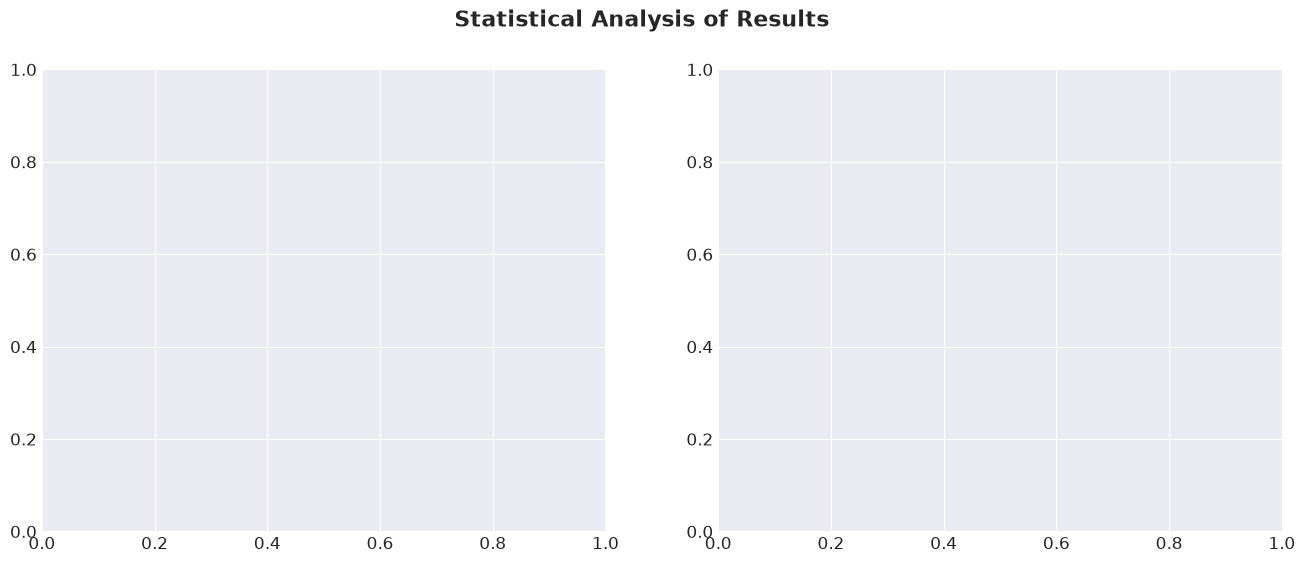

In [14]:
# ============================================================================
# 3. Execute Analysis
# ============================================================================

if df_summary is not None:
    print("\n" + "="*80)
    print("Generating Performance Analysis Charts")
    print("="*80)
    
    # Create results folder if it doesn't exist
    os.makedirs("results", exist_ok=True)
    
    # 1. Main comparison plots
    print("\n1. Creating main comparison plots...")
    create_comparison_plots(df_summary)
    
    # 2. Heatmap plots
    print("2. Creating heatmap plots...")
    create_heatmap(df_summary)
    
    # 3. Phase comparison
    print("3. Creating phase comparison plots...")
    create_phase_comparison(df_summary)
    
    # 4. Scalability analysis
    print("4. Creating scalability analysis plots...")
    create_scalability_analysis(df_summary)
    
    # 5. Statistical analysis
    print("5. Creating statistical analysis plots...")
    create_statistical_summary(df_summary)
    
    print("\nAll charts have been saved to the 'results' folder.")

In [ ]:
# ============================================================================
# 4. Statistical Summary Display
# ============================================================================

if df_summary is not None:
    print("\n" + "="*80)
    print("Statistical Summary of Results")
    print("="*80)
    
    # Group by key length
    print("\nAverage Total Time by Key Length:")
    print(df_summary.groupby('bits')['total_avg_ms'].agg(['mean', 'std', 'min', 'max']).round(2))
    
    print("\nAverage Total Time by Number of Clients:")
    print(df_summary.groupby('num_clients')['total_avg_ms'].agg(['mean', 'std', 'min', 'max']).round(2))
    
    # Best and worst configurations
    best_config = df_summary.loc[df_summary['total_avg_ms'].idxmin()]
    worst_config = df_summary.loc[df_summary['total_avg_ms'].idxmax()]
    
    print(f"\nBest Configuration: {best_config['bits']}-bit, {best_config['num_clients']} clients")
    print(f"  Total Time: {best_config['total_avg_ms']:.2f} ms")
    
    print(f"\nWorst Configuration: {worst_config['bits']}-bit, {worst_config['num_clients']} clients")
    print(f"  Total Time: {worst_config['total_avg_ms']:.2f} ms")
    
    # Parameter effect analysis
    print("\nEffect of Increasing Key Length on Total Time:")
    for bits in sorted(df_summary['bits'].unique()):
        avg_time = df_summary[df_summary['bits'] == bits]['total_avg_ms'].mean()
        print(f"  {bits}-bit: {avg_time:.2f} ms")
    
    print("\nEffect of Increasing Number of Clients on Total Time:")
    for num_clients in sorted(df_summary['num_clients'].unique()):
        avg_time = df_summary[df_summary['num_clients'] == num_clients]['total_avg_ms'].mean()
        print(f"  {num_clients} clients: {avg_time:.2f} ms")

print("\nAnalysis complete! All charts have been saved to the 'results' folder.")